# Essendon in the 2022 State Election

The 2022 Victorian state election is a strong starting point for examining voter behaviour in Essendon for thsi project.

Here we look at first-preference results and the difference between Labor's primary vote and final two-candidate-preferred result.

Source: [VEC](https://www.vec.vic.gov.au/results/state-election-results/2022-state-election-results/results-by-district/essendon-district-results)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

results2022 = pd.read_csv("../data/raw/Essendon2022.csv")
results2018 = pd.read_csv("../data/raw/Essendon2018.csv")

In [2]:
formalVotes = results2022["votes"].sum()
assert formalVotes == 41867

results2022["votePct"] = 100 * results2022["votes"] / formalVotes
results2022 = results2022.sort_values("votes", ascending=False)

results2022[["candidate", "party", "votes", "votePct"]].round(2)

,candidate,party,votes,votePct
6,Danny Pearson,Australian Labor Party,17196,41.07
5,Angelo Baronessa,Liberal,12331,29.45
2,Jared Prentis,Australian Greens,6344,15.15
3,Daniel Nair Dadich,Victorian Socialists,1951,4.66
0,Gayle Williams,Animal Justice Party,1173,2.80
4,Nicholas Hope,Fiona Patten's Reason Party,1018,2.43
1,David Wright,Freedom Party of Victoria,1006,2.40
7,Margaret Muir,Family First Victoria,848,2.03


## Visualising the result

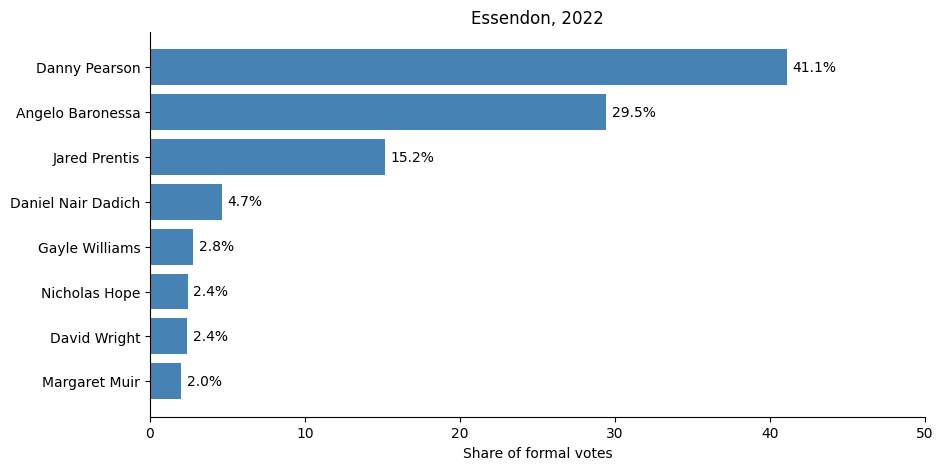

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

plotData = results2022.sort_values("votes")
bars = ax.barh(plotData["candidate"], plotData["votePct"], color="steelblue")
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_xlim(0, 50)
ax.set_xlabel("Share of formal votes")
ax.set_title("Essendon, 2022")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## First prefs vs final result

In [5]:
laborPrimary = results2022.loc[
    results2022["party"] == "Australian Labor Party", "votePct"
].iloc[0]
laborFinal = 100 * 26146 / formalVotes

print(f"Difference: {laborFinal - laborPrimary:.2f} pp")

Difference: 21.38 pp


In [6]:
majorParties = {
    "Australian Labor Party": "Labor",
    "Liberal": "Liberal",
    "Australian Greens": "Greens"
}


def partyShare(results):
    data = results.copy()
    data["group"] = data["party"].map(majorParties).fillna("Others")
    votes = data.groupby("group")["votes"].sum()

    shares = 100 * votes / votes.sum()

    return shares.reindex(["Labor", "Liberal", "Greens", "Others"], fill_value=0)


comparison = pd.DataFrame({
    "2018": partyShare(results2018),
    "2022": partyShare(results2022),
})
comparison["SwingPP"] = comparison["2022"] - comparison["2018"]
comparison.round(2)

,2018,2022,SwingPP
group,,,
Labor,46.23,41.07,-5.16
Liberal,27.52,29.45,1.93
Greens,16.81,15.15,-1.66
Others,9.44,14.32,4.88


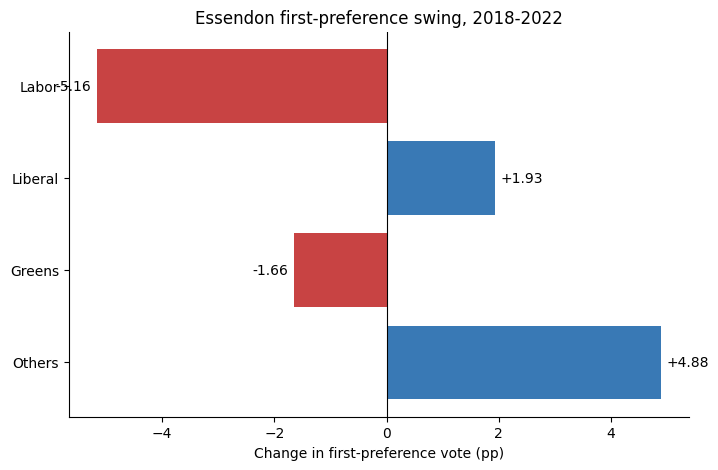

In [7]:
colours = ["#c84343" if x < 0 else "#3979b5" for x in comparison["SwingPP"]]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(comparison.index, comparison["SwingPP"], color=colours)

ax.axvline(0, color="black", linewidth=0.8)
ax.bar_label(bars, fmt="%+.2f", padding=4)
ax.set_xlabel("Change in first-preference vote (pp)")
ax.set_title("Essendon first-preference swing, 2018-2022")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [9]:
laborPrimary = comparison.loc["Labor", ["2018", "2022"]]

labor2CP = pd.Series({
    "2018": 100 * 27315 / 41472,
    "2022": 100 * 26146 / 41867
})
laborComparison = pd.DataFrame({
    "Primary": laborPrimary,
    "Two-candidate Preferred": labor2CP
})

laborComparison.round(2)

,Primary,Two-candidate Preferred
2018,46.23,65.86
2022,41.07,62.45


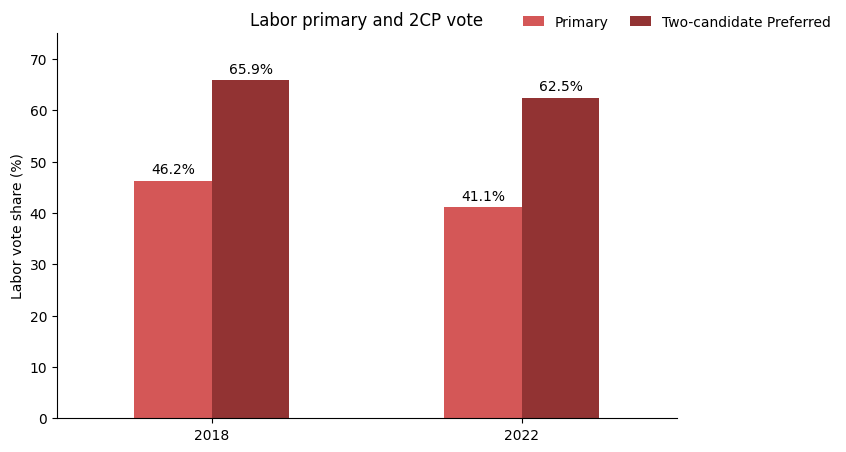

In [16]:
ax = laborComparison.plot(kind="bar", figsize=(
    8, 5), color=["#d45757", "#923333"], rot=0)
ax.set_ylim(0, 75)
ax.set_ylabel("Labor vote share (%)")
ax.set_xlabel("")
ax.set_title("Labor primary and 2CP vote")
ax.legend(
    ncol=2,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(1, 1.08),
    columnspacing=1.5,
    handlelength=1.5
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.spines[["top", "right"]].set_visible(False)
plt.show()